In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import seaborn as sns

from src.data.load import load_cmapss
from src.features.rul import add_rul

df = add_rul(load_cmapss("../data/raw"))
df.head()

,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,125
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,125
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,125
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,125
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,125


In [2]:
print(df.shape)
print(df.isna().sum().sum(), "valores nulos")
print(df["unit"].nunique(), "motores")
df.describe().T

(20631, 27)
0 valores nulos
100 motores


,count,mean,std,min,25%,50%,75%,max
unit,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
s1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
s2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


In [3]:
std = df.filter(regex=r"^s\d+$").std().sort_values()
std.head(10)

s1     0.000000e+00
s10    0.000000e+00
s19    0.000000e+00
s18    0.000000e+00
s16    3.469531e-18
s5     5.329200e-15
s6     1.388985e-03
s15    3.750504e-02
s8     7.098548e-02
s13    7.191892e-02
dtype: float64

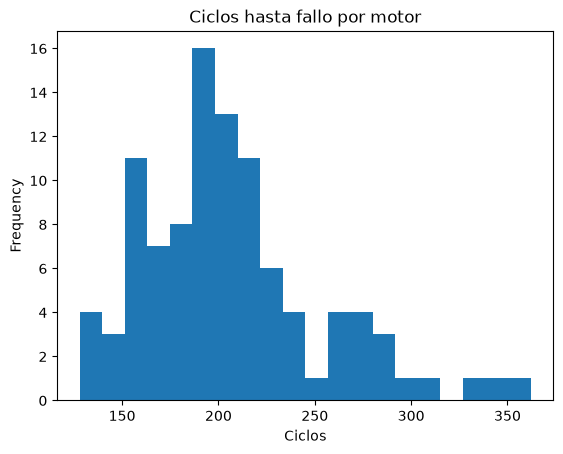

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

In [4]:
life = df.groupby("unit")["cycle"].max()
life.plot.hist(bins=20, title="Ciclos hasta fallo por motor")
plt.xlabel("Ciclos")
plt.show()
life.describe()

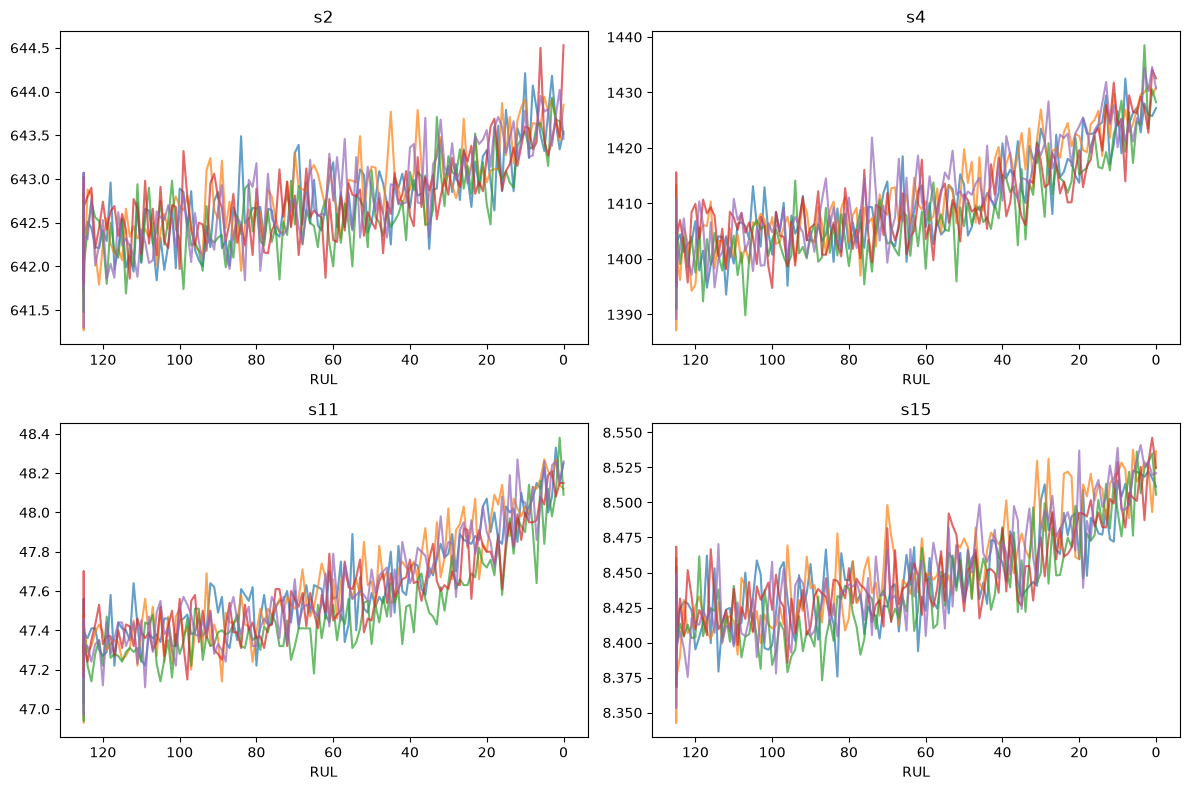

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, s in zip(axes.ravel(), ["s2", "s4", "s11", "s15"]):
    for u in [1, 2, 3, 4, 5]:
        d = df[df["unit"] == u]
        ax.plot(d["rul"], d[s], alpha=0.7)
    ax.set_title(s)
    ax.invert_xaxis()
    ax.set_xlabel("RUL")
plt.tight_layout()
plt.show()

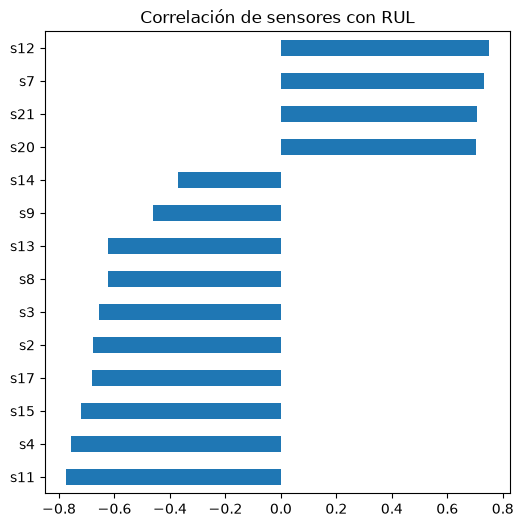

In [6]:
from src.features.rolling import useful_sensors

cols = useful_sensors(df) + ["rul"]
corr = df[cols].corr()["rul"].drop("rul").sort_values()
corr.plot.barh(figsize=(6, 6), title="Correlación de sensores con RUL")
plt.show()

## Conclusiones

- **Datos limpios:** 20.631 filas, 100 motores, 0 valores nulos. La vida de los motores va de 128 a 362 ciclos (media ~206), con una distribución sesgada a la derecha.
- **Sensores descartados:** s1, s5, s6, s10, s16, s18 y s19 tienen desviación estándar ~0 (constantes), así que no aportan información. También `setting_3` es constante. Nos quedamos con 14 sensores útiles.
- **Sensores más correlacionados con el RUL:**
  - Correlación negativa (suben al acercarse al fallo): s11, s4, s15, s17, s2, s3.
  - Correlación positiva (bajan al acercarse al fallo): s12, s7, s21, s20.
  - Los más informativos son s11, s12, s4, s7 y s21 (|correlación| ≈ 0.7-0.8).
- **Tendencia de degradación:** al acercarse el RUL a 0, la señal deriva de forma clara (s2, s4, s11 y s15 suben). Al principio de la vida los sensores son estables y la degradación se acelera en los últimos ~50-60 ciclos.
- **Ruido:** los sensores son muy ruidosos ciclo a ciclo, lo que justifica usar medias móviles y pendientes como features en el siguiente paso.